
# 1. simulazioni esponenziali per tempi di vita

In [1]:
import numpy as np
import pandas as pd
from itertools import cycle
from matplotlib.path import Path as MplPath
import tifffile
import sys
from pathlib import Path
import plotly.graph_objects as go


#librerie personali (da sistemare perché fanno schifo)

import random
# from scipy.stats import norm, chi2
import scipy.stats as stats
import matplotlib.pyplot as plt
from iminuit import Minuit, cost
import sys

import lib.randgen
import lib.my_stats

<h3> Data generation

In [2]:
# estimate of tau 

τ_true = 4.0 # ns
N_evt = 1000

tempi = np.random.exponential(scale = τ_true, size=N_evt)
n, xe = np.histogram(tempi, bins='auto')   
    # I'm saving the data in a histogram to use it later for the chi-square test
    # xe = bin edges, n = bin heights


<h3> Method 1: Tau as arithmetical average of the data set

In [3]:
τ_fit, τ_err = np.mean(tempi), np.std(tempi) / np.sqrt(N_evt)    # standard error of the mean = std / sqrt(N)
print(f"\nFit result: tau = {τ_fit:.3f} ± {τ_err:.3f} ns")


# fit results
print('\n')
chi2 = np.sum((n - N_evt * (np.exp(-xe[:-1]/τ_fit) - np.exp(-xe[1:]/τ_fit)))**2 / (N_evt * (np.exp(-xe[:-1]/τ_fit) - np.exp(-xe[1:]/τ_fit))))
ndof = len(n) - 1
chi2_red = chi2 / ndof
p_value = 1 - stats.chi2.cdf(chi2, ndof)  

print(f"Chi-squared: {chi2:.3f}")
print(f"Reduced Chi-squared: {chi2_red:.3f}")
print(f"dof: {ndof}")  # number of events minus number of fitted parameters per bin
print(f"pval: {p_value:.3f}")


Fit result: tau = 4.003 ± 0.131 ns


Chi-squared: 31.778
Reduced Chi-squared: 0.883
dof: 36
pval: 0.670


<h3> Method 2: Tau as parameter from exponential fit


needed because first method is only good for a pure exponential and I may need to add noise in the future

In [20]:

# CDF F(t) = 1 - e^(-t/tau)
# not using scipy version because I want tau as a parameter
def expon_cdf(x, τ):
    return 1.0 - np.exp(-x / τ)   # I need cdf for the binned likelihood 

c = cost.BinnedNLL(n, xe, expon_cdf)
m = Minuit(c, τ=2)
m.migrad()

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 27.28 (χ²/ndof = 0.8)      │              Nfcn = 27               │
│ EDM = 1.47e-06 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬──────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼──────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ τ    │   4.00    │   0.13    │            │            │         │         │       │
└───┴──────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌───┬────────┐
│   │      τ │
├───┼────────┤
│ τ │ 0.0161 │
└───┴────────┘

<h3> Alternative data plot for method 2

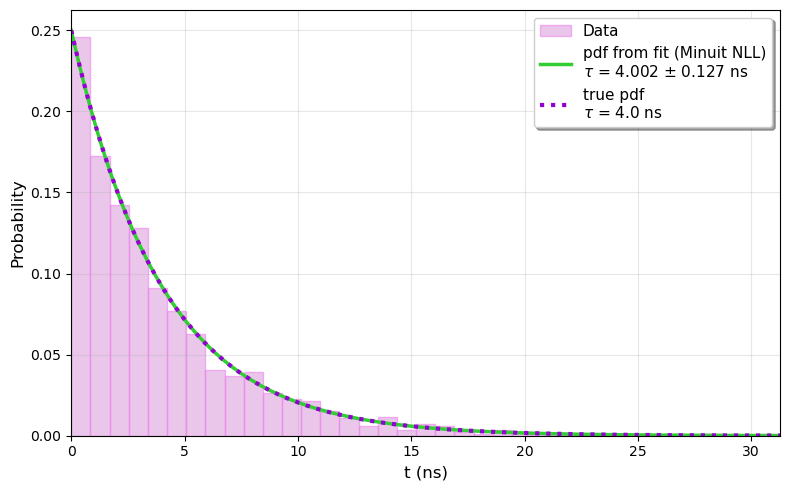

In [5]:
plt.figure(figsize=(8, 5))


# histogram
plt.hist(tempi, bins=xe, density=True, alpha=0.6, color='plum', 
         edgecolor='violet', label='Data')                          #leaving all the details of the histogram so I can copy from here

# fitted pdf + true pdf
x_plot = np.linspace(0, xe[-1], 500)
pdf_fit = (1.0 / τ_fit) * np.exp(-x_plot / τ_fit)
pdf_true = (1.0 / τ_true) * np.exp(-x_plot / τ_true)

plt.plot(x_plot, pdf_fit, color='limegreen', linewidth=2.5, 
         label=f'pdf from fit (Minuit NLL)\n$\\tau$ = {τ_fit:.3f} $\\pm$ {τ_err:.3f} ns')
plt.plot(x_plot, pdf_true, color='darkviolet', linestyle='dotted', linewidth=3, 
         label=f'true pdf\n$\\tau$ = {τ_true:.1f} ns')

# cosmetics
plt.xlabel("t (ns)", fontsize=12)
plt.ylabel("Probability", fontsize=12)
plt.legend(fontsize=11, frameon=True, shadow=True)
plt.grid(alpha=0.3)
plt.xlim(0, xe[-1])

plt.tight_layout()
plt.show()

<h3> Method 3: unbinned log-likelihood

In [21]:
c = cost.UnbinnedNLL(tempi, lambda x, τ: (1.0 / τ) * np.exp(-x / τ))

m1 = Minuit(c, τ=1)
m1.migrad()

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 4774                       │              Nfcn = 33               │
│ EDM = 5.61e-09 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬──────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼──────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ τ    │   4.00    │   0.13    │            │            │         │         │       │
└───┴──────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌───┬───────┐
│   │     τ │
├───┼───────┤
│ τ │ 0.016 │
└───┴───────┘